# 02 · Windows, prompt, training targets and stitching

Some transcripts are longer than the 8,192-token input budget. Rather than truncate them, every video is cut into **windows**:
* Each window *owns* a disjoint block of sentences `[A, B)`.
* Each window also sees up to 16 sentences of context on each side, `[L, R)`.
* The model must list `L` first; it is a processing anchor, not a claimed boundary.
* After generation, only the chapter starts inside `[A, B)` are kept.

The owned blocks tile the transcript exactly, so stitching is a plain concatenation. The windows are identical for all four backbones because each window is sized to fit the budget under all four tokenizers at once.

In [1]:
%matplotlib inline
import json, statistics
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from nbcommon import *

pd.set_option("display.max_colwidth", 80)
RUN_GPU = False   # True only on the training/inference machine (needs the models and a GPU)
print("project:", ROOT.name, "| run outputs read from:", A.relative_to(ROOT))

project: FinalProject | run outputs read from: artifacts


## 1. One multi-window video from the dev pack

In [2]:
from chaptering.windowing import build_window_prompt, parse_window_outline, stitch_window_predictions

windows = defaultdict(list)
for row in load_jsonl(DEV_WINDOWS):
    windows[row["window"]["video_id"]].append(row["window"])
records = by_id(DEV_RECORDS)
video = sorted(v for v, ws in windows.items() if len(ws) == 3)[0]
ws = windows[video]
n = len(records[video]["sentences"])
display(pd.DataFrame([{k: w[k] for k in ["window_index", "L", "A", "B", "R", "left_context_count", "right_context_count"]}
                      | {"tokens (M1/M2/E1/E2)": "/".join(str(w["input_token_counts"][m]) for m in ["M1", "M2", "E1", "E2"])}
                      for w in ws]).set_index("window_index"))
cores = [(w["A"], w["B"]) for w in ws]
assert cores[0][0] == 0 and cores[-1][1] == n and all(a[1] == b[0] for a, b in zip(cores, cores[1:]))
print(f"video {video}: {n} sentences; owned blocks tile [0, {n}) exactly:", cores)

,L,A,B,R,left_context_count,right_context_count,tokens (M1/M2/E1/E2)
window_index,,,,,,,
0,0,0,306,322,0,16,8093/8161/8160/8160
1,290,306,585,601,16,16,8091/8154/8142/8142
2,569,585,665,665,16,0,2677/2691/2678/2678


video EYYNRubHIno: 665 sentences; owned blocks tile [0, 665) exactly: [(0, 306), (306, 585), (585, 665)]


## 2. The prompt every model receives (window 2)

In [3]:
prompt = build_window_prompt(ws[1])
print(prompt[:1800], "\n...")

Divide the visible transcript into contiguous topical chapters and give each a concise, specific title supported only by visible text. Do not rewrite the transcript. Bracketed numbers are GLOBAL sentence indices. A chapter start is the index of its first sentence. Visible context is [290,601); the ownership region is [306,585). Always include start 290 as the first item: it is a processing anchor, not evidence of a real cut. Include other chapter starts throughout visible context when its content changes. Ownership edges alone do not create chapter boundaries. Only starts inside the ownership region will be retained after processing all windows. Choose chapter count from visible content. Use strictly increasing integer starts from 290 through 600, with nonempty titles. In your final answer return only one JSON object with exactly this structure: {"chapters":[{"start":290,"title":"Short title"}]}. Do not put commentary or a Markdown fence around the final JSON.

TRANSCRIPT
[290] You can

## 3. Training targets

A training window's target is the gold chapter JSON inside its visible range. Titles that the window cannot fully support are replaced by the placeholder `Chapter` and **masked out of the loss**. This applies to the processing anchor, chapters it does not own, and chapters cut by the window edge.

In [4]:
train_row = next(r for r in load_jsonl(TRAIN_WINDOWS) if r["window"]["window_index"] == 1)
print("window", {k: train_row["window"][k] for k in ["video_id", "L", "A", "B", "R"]})
print("target:", train_row["target"]["target_json"][:500])
print("masked character spans:", train_row["target"]["masked_target_spans"][:6])
print("title stats:", train_row["target"]["title_supervision_stats"])

window {'video_id': 'xMs4ER1rcLg', 'L': 252, 'A': 268, 'B': 538, 'R': 554}
target: {"chapters":[{"start":252,"title":"Chapter"},{"start":278,"title":"counter2.html"},{"start":353,"title":"counter3.html"},{"start":369,"title":"Variables"},{"start":386,"title":"variables0.html"},{"start":392,"title":"variables1.html"},{"start":416,"title":"variables2.html"},{"start":517,"title":"Chapter"}]}
masked character spans: [[35, 42], [297, 304]]
title stats: {'emitted_chapters': 8, 'supervised_titles': 6, 'masked_titles': 2, 'masked_processing_anchor_titles': 1, 'masked_unowned_titles': 1, 'masked_partial_or_synthetic_titles': 2, 'processing_anchor_is_true_chapter_start': False}


## 4. Stitching: gold window outlines → whole-video chapters

In [5]:
# Use each window's gold window target as a stand-in for a model answer. Stitching keeps only owned starts, so the
# result must equal the gold chapter starts of the whole video.
from chaptering.windowing import window_training_target
answers = []
for w in ws:
    target_json = window_training_target(records[video], w)["target_json"]
    answers.append({"video_id": video, "window_index": w["window_index"], "status": "ok",
                    "chapters": parse_window_outline(target_json, w)})
stitched = stitch_window_predictions(ws, answers, run_id="gold-demo")
print("status:", stitched["status"])
print("stitched starts:", [c["start"] for c in stitched["chapters"]])
print("gold starts:    ", records[video]["reference"]["chapter_starts"])
assert [c["start"] for c in stitched["chapters"]] == records[video]["reference"]["chapter_starts"]

status: ok
stitched starts: [0, 239, 366]
gold starts:     [0, 239, 366]


## 5. Window packs used in the experiments

,videos,windows,1 window,2,3,4+,max windows
pack,,,,,,,
pilot train (LoRA),1000,1306,841,93,33,33,12
dev (200 validation),200,270,163,22,7,8,8
test,1448,1905,1214,143,40,51,10


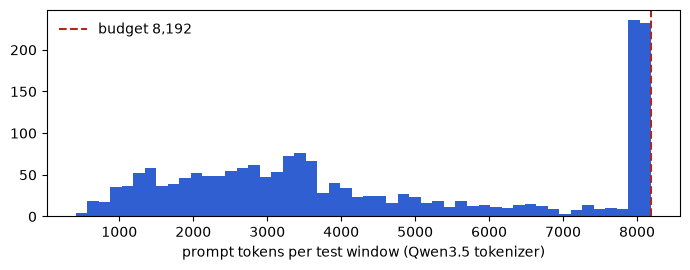

In [6]:
rows = []
for name, path in [("pilot train (LoRA)", TRAIN_WINDOWS), ("dev (200 validation)", DEV_WINDOWS), ("test", TEST_WINDOWS)]:
    count = Counter(json.loads(line)["window"]["video_id"] for line in open(path))
    dist = Counter(min(c, 4) for c in count.values())
    rows.append({"pack": name, "videos": len(count), "windows": sum(count.values()), "1 window": dist[1], "2": dist[2],
                 "3": dist[3], "4+": dist[4], "max windows": max(count.values())})
display(pd.DataFrame(rows).set_index("pack"))
tokens = [json.loads(line)["window"]["input_token_counts"]["M1"] for line in open(TEST_WINDOWS)]
plt.figure(figsize=(7, 2.8)); plt.hist(tokens, bins=50, color="#2f5fd0")
plt.axvline(8192, color="#b3261e", linestyle="--", label="budget 8,192")
plt.xlabel("prompt tokens per test window (Qwen3.5 tokenizer)"); plt.legend(frameon=False); plt.tight_layout()

In [7]:
# The test pack copies every setting from the validation pack and is built once, after the freeze.
test_manifest = load_json(TEST_PACK / "manifest.json")
print(test_manifest["purpose"]); print(test_manifest["settings"])
run(["python", "scripts/prepare_test.py"], RUN_GPU)

held-out test pack, built once after the freeze
{'train_videos': 16377, 'validation_videos': 1446, 'input_tokens': 8192, 'core_sentences': 100000, 'context_sentences': 16, 'seed': 393, 'census_all': False, 'core_search': 'bisect'}
[not run here; RUN_GPU=False]  $ python scripts/prepare_test.py
